# AITR Lab 02 — Hallucination Detection Experiments

This notebook reproduces a controlled comparison on HaluEval QA:
1. TF-IDF + Logistic Regression
2. TF-IDF + Linear SVM
3. GPT-2 conditional candidate-answer likelihood (optional GPU step)

**Important:** this scores supplied answer candidates; it does not evaluate GPT-2's own generations. It does not implement semantic entropy. Run top-to-bottom, inspect outputs, and save the executed notebook before submission.

In [1]:
import os, sys, json, time, random, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
OUT = Path("results")
OUT.mkdir(exist_ok=True)
FIG = OUT / "figures"
FIG.mkdir(exist_ok=True)
print("Python:", sys.version)
print("Platform:", platform.platform())

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39


## 1. Environment check

In [2]:
try:
    import torch
    print("PyTorch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
except Exception as e:
    print("PyTorch check failed:", repr(e))
try:
    import sklearn
    print("scikit-learn:", sklearn.__version__)
except Exception as e:
    print(repr(e))

PyTorch: 2.11.0+cpu
CUDA available: False
scikit-learn: 1.6.1


## 2. Load HaluEval QA from the official repository

In [11]:
DATA_URL = "https://raw.githubusercontent.com/RUCAIBox/HaluEval/main/data/qa_data.json"
df = pd.read_json(DATA_URL)
required = ["knowledge", "question", "right_answer", "hallucinated_answer"]
missing = [c for c in required if c not in df.columns]
assert not missing, f"Missing expected columns: {missing}"
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head(3))
assert len(df) >= 1000

Shape: (10000, 4)
Columns: ['knowledge', 'question', 'right_answer', 'hallucinated_answer']


,knowledge,question,right_answer,hallucinated_answer
0,Arthur's Magazine (1844–1846) was an American ...,Which magazine was started first Arthur's Maga...,Arthur's Magazine,First for Women was started first.
1,The Oberoi family is an Indian family that is ...,The Oberoi family is part of a hotel company t...,Delhi,The Oberoi family's hotel company is based in ...
2,"Allison Beth ""Allie"" Goertz (born March 2, 199...",Musician and satirist Allie Goertz wrote a son...,President Richard Nixon,"Allie Goertz wrote a song about Milhouse, a po..."


## 3. Build paired candidate-answer instances

In [5]:
sample = df.sample(n=1000, random_state=SEED).reset_index(drop=True).copy()
sample["group_id"] = sample["knowledge"].fillna("").astype(str) + " || " + sample["question"].fillna("").astype(str)

rows = []
for idx, r in sample.iterrows():
    prefix = f"Question: {r['question']}\nKnowledge: {r['knowledge']}\nCandidate answer: "
    rows.append({"pair_id": idx, "group_id": r["group_id"], "question": r["question"],
                 "knowledge": r["knowledge"], "answer": r["right_answer"],
                 "label": 0, "answer_type": "right", "text": prefix + str(r["right_answer"])})
    rows.append({"pair_id": idx, "group_id": r["group_id"], "question": r["question"],
                 "knowledge": r["knowledge"], "answer": r["hallucinated_answer"],
                 "label": 1, "answer_type": "hallucinated", "text": prefix + str(r["hallucinated_answer"])})
data = pd.DataFrame(rows)
print("Instances:", data.shape, "Label counts:", data["label"].value_counts().to_dict())
assert data.groupby("pair_id")["label"].nunique().eq(2).all()
data[["pair_id","answer_type","label","question","answer"]].head()

Instances: (2000, 8) Label counts: {0: 1000, 1: 1000}


,pair_id,answer_type,label,question,answer
0,0,right,0,The manager in which Mark Lazarus clashed with...,1948 and 1964
1,0,hallucinated,1,The manager in which Mark Lazarus clashed with...,Mark Lazarus clashed with the manager of Wolve...
2,1,right,0,"No. 11 Squadron RAAF was based at what base, 2...",RAAF Base Edinburgh
3,1,hallucinated,1,"No. 11 Squadron RAAF was based at what base, 2...","RAAF Base Edinburgh, located in Australia."
4,2,right,0,Which movie starring Kim Roi-ha is based on Ko...,Memories of Murder


## 4. Group split and baseline training

Train: (1600, 8) Test: (400, 8)
Train labels: {0: 800, 1: 800}
Test labels: {0: 200, 1: 200}

 TF-IDF + Logistic Regression
              precision    recall  f1-score   support

       right       0.62      0.68      0.65       200
hallucinated       0.64      0.58      0.61       200

    accuracy                           0.63       400
   macro avg       0.63      0.63      0.63       400
weighted avg       0.63      0.63      0.63       400



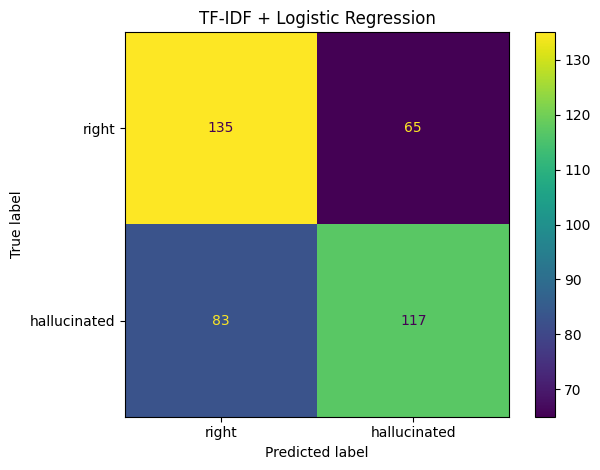


 TF-IDF + Linear SVM
              precision    recall  f1-score   support

       right       0.62      0.73      0.67       200
hallucinated       0.67      0.54      0.60       200

    accuracy                           0.64       400
   macro avg       0.64      0.64      0.63       400
weighted avg       0.64      0.64      0.63       400



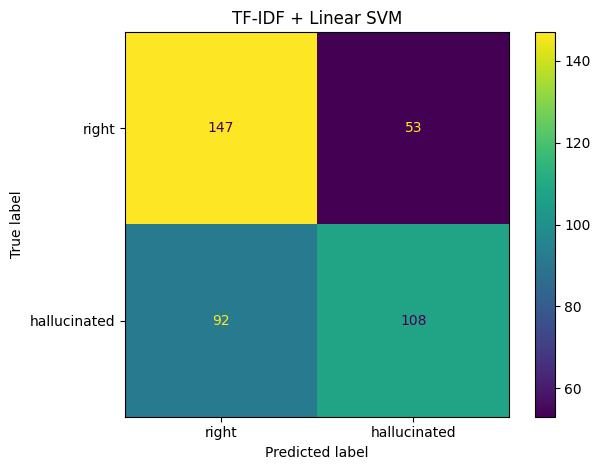

,model,accuracy,precision,recall,f1,auroc,auprc,fit_time_seconds
0,TF-IDF + Logistic Regression,0.6300,0.642857,0.585,0.612565,0.686175,0.687637,0.786455
1,TF-IDF + Linear SVM,0.6375,0.670807,0.540,0.598338,0.700900,0.705883,0.706101


In [6]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(data["text"], data["label"], groups=data["group_id"]))
train = data.iloc[train_idx].copy()
test = data.iloc[test_idx].copy()
assert set(train["group_id"]).isdisjoint(set(test["group_id"])), "Group leakage detected"
print("Train:", train.shape, "Test:", test.shape)
print("Train labels:", train.label.value_counts().to_dict())
print("Test labels:", test.label.value_counts().to_dict())

models = {
    "TF-IDF + Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(max_features=20000, ngram_range=(1,2), min_df=2)),
        ("clf", LogisticRegression(max_iter=1000, random_state=SEED))
    ]),
    "TF-IDF + Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(max_features=20000, ngram_range=(1,2), min_df=2)),
        ("clf", LinearSVC(random_state=SEED))
    ])
}
metric_rows, prediction_frames = [], []
for name, model in models.items():
    t0 = time.time()
    model.fit(train["text"], train["label"])
    fit_time = time.time() - t0
    pred = model.predict(test["text"])
    clf = model.named_steps["clf"]
    if hasattr(clf, "predict_proba"):
        score = model.predict_proba(test["text"])[:, 1]
    else:
        score = model.decision_function(test["text"])
    row = {
        "model": name,
        "accuracy": accuracy_score(test["label"], pred),
        "precision": precision_score(test["label"], pred, zero_division=0),
        "recall": recall_score(test["label"], pred, zero_division=0),
        "f1": f1_score(test["label"], pred, zero_division=0),
        "auroc": roc_auc_score(test["label"], score),
        "auprc": average_precision_score(test["label"], score),
        "fit_time_seconds": fit_time
    }
    metric_rows.append(row)
    pf = test[["pair_id","group_id","question","knowledge","answer","answer_type","label"]].copy()
    pf["model"] = name
    pf["prediction"] = pred
    pf["score"] = score
    prediction_frames.append(pf)
    print("\n", name)
    print(classification_report(test["label"], pred, target_names=["right","hallucinated"], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(test["label"], pred, display_labels=["right","hallucinated"])
    plt.title(name)
    plt.tight_layout()
    plt.savefig(FIG / (name.lower().replace(" ","_").replace("+","plus").replace("-","_") + "_confusion.png"), dpi=160)
    plt.show()

metrics_df = pd.DataFrame(metric_rows)
predictions_df = pd.concat(prediction_frames, ignore_index=True)
metrics_df.to_csv(OUT / "baseline_metrics.csv", index=False)
predictions_df.to_csv(OUT / "test_predictions.csv", index=False)
predictions_df[predictions_df["model"] == "TF-IDF + Linear SVM"].to_csv(OUT / "svm_test_predictions.csv", index=False)
display(metrics_df)

## 5. Deeper analysis: errors and false predictions

In [7]:
# Use actual outputs from the current run; examples are saved for inspection.
error_frames = []
for model_name, frame in predictions_df.groupby("model"):
    err = frame[frame["prediction"] != frame["label"]].copy()
    err["error_type"] = np.where((err["label"] == 1) & (err["prediction"] == 0),
                                 "false_negative_hallucination_missed",
                                 "false_positive_right_flagged")
    error_frames.append(err)
errors = pd.concat(error_frames, ignore_index=True) if error_frames else pd.DataFrame()
errors.to_csv(OUT / "error_analysis.csv", index=False)
print("Error rows:", len(errors))
display(errors[["model","error_type","answer_type","question","answer","label","prediction","score"]].head(20))

Error rows: 293


,model,error_type,answer_type,question,answer,label,prediction,score
0,TF-IDF + Linear SVM,false_positive_right_flagged,right,Which dinosaur was named after the province wh...,Riojasaurus,0,1,0.103423
1,TF-IDF + Linear SVM,false_positive_right_flagged,right,Lookwell was a television pilot written and pr...,Brandon Tartikoff,0,1,0.101282
2,TF-IDF + Linear SVM,false_positive_right_flagged,right,Which player singed to Bayern Munich was born ...,Dante Bonfim Costa Santos (born 18 October 1983),0,1,0.119245
3,TF-IDF + Linear SVM,false_negative_hallucination_missed,hallucinated,what does Street Fight and Cory Booker have in...,Street Fight and Cory Booker have in common th...,1,0,-0.357310
4,TF-IDF + Linear SVM,false_positive_right_flagged,right,Who won the singles title at a 1973 tennis tou...,Margaret Court,0,1,0.223673
5,TF-IDF + Linear SVM,false_negative_hallucination_missed,hallucinated,What british literary critic lauded Stephen Bo...,"Stephen Booth himself praised his essay ""On th...",1,0,-0.385335
6,TF-IDF + Linear SVM,false_positive_right_flagged,right,How many golden also did Jan Tauren win at the...,three,0,1,0.025536
7,TF-IDF + Linear SVM,false_negative_hallucination_missed,hallucinated,"Which rocket propelled weapon, sometimes refer...",Colonel Skinner developed a stove.,1,0,-0.046403
8,TF-IDF + Linear SVM,false_negative_hallucination_missed,hallucinated,What occupation do Beth Gibbons and Han Seung-...,Beth Gibbons and Han Seung-yeon are both perfo...,1,0,-0.267288
9,TF-IDF + Linear SVM,false_negative_hallucination_missed,hallucinated,American Drag racer Antron Brown has been know...,Antron Brown has won three championships but t...,1,0,-0.040007


## 6. GPT-2 conditional answer likelihood (optional; use GPU if available)

In [8]:
# This is candidate-answer scoring, not generation and not semantic entropy.
# Score answer tokens only, conditioned on knowledge + question.
RUN_GPT2 = True
if RUN_GPT2:
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM
    checkpoint = "gpt2"
    device = "cuda" if torch.cuda.is_available() else "cpu"
    tokenizer = AutoTokenizer.from_pretrained(checkpoint)
    lm = AutoModelForCausalLM.from_pretrained(checkpoint).to(device)
    lm.eval()
    records = []
    small = sample.head(100).copy()
    for i, r in small.iterrows():
        context = f"Knowledge: {r['knowledge']}\nQuestion: {r['question']}\nAnswer:"
        for label, answer in [(0, r["right_answer"]), (1, r["hallucinated_answer"])]:
            answer = str(answer)
            full_text = context + " " + answer
            enc = tokenizer(full_text, return_tensors="pt", truncation=True, max_length=1024)
            input_ids = enc["input_ids"].to(device)
            context_ids = tokenizer(context + " ", return_tensors="pt", truncation=True, max_length=1024)["input_ids"]
            answer_start = min(context_ids.shape[1], input_ids.shape[1]-1)
            with torch.no_grad():
                logits = lm(input_ids).logits[:, :-1, :]
                targets = input_ids[:, 1:]
                log_probs = torch.log_softmax(logits, dim=-1).gather(-1, targets.unsqueeze(-1)).squeeze(-1)
            # targets position j predicts input token j+1; include answer-token targets only.
            start_target = max(answer_start - 1, 0)
            answer_log_probs = log_probs[:, start_target:]
            if answer_log_probs.numel() == 0:
                mean_lp = float("nan")
            else:
                mean_lp = answer_log_probs.mean().item()
            records.append({
                "pair_id": int(i), "label": int(label),
                "answer_type": "right" if label == 0 else "hallucinated",
                "question": str(r["question"]), "answer": answer,
                "mean_token_log_probability": mean_lp,
                "negative_mean_token_log_probability": -mean_lp,
                "model": checkpoint
            })
    likelihood_df = pd.DataFrame(records).dropna(subset=["negative_mean_token_log_probability"])
    likelihood_df.to_csv(OUT / "token_likelihood_results.csv", index=False)
    from sklearn.metrics import roc_auc_score, average_precision_score
    y = likelihood_df["label"].to_numpy()
    u = likelihood_df["negative_mean_token_log_probability"].to_numpy()
    print("Original direction AUROC:", round(roc_auc_score(y, u), 4))
    print("Original direction AUPRC:", round(average_precision_score(y, u), 4))
    print("Reversed AUROC:", round(roc_auc_score(y, -u), 4))
    print("Reversed AUPRC:", round(average_precision_score(y, -u), 4))
    display(likelihood_df.groupby("answer_type")["negative_mean_token_log_probability"].agg(["count","mean","median","std"]))
    display(likelihood_df.head())

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Original direction AUROC: 0.6939
Original direction AUPRC: 0.5778
Reversed AUROC: 0.3061
Reversed AUPRC: 0.3802


,count,mean,median,std
answer_type,,,,
hallucinated,100,2.024116,1.687378,1.619434
right,100,1.974734,0.434273,2.839511


,pair_id,label,answer_type,question,answer,mean_token_log_probability,negative_mean_token_log_probability,model
0,0,0,right,The manager in which Mark Lazarus clashed with...,1948 and 1964,-2.820268,2.820268,gpt2
1,0,1,hallucinated,The manager in which Mark Lazarus clashed with...,Mark Lazarus clashed with the manager of Wolve...,-2.029197,2.029197,gpt2
2,1,0,right,"No. 11 Squadron RAAF was based at what base, 2...",RAAF Base Edinburgh,-0.124763,0.124763,gpt2
3,1,1,hallucinated,"No. 11 Squadron RAAF was based at what base, 2...","RAAF Base Edinburgh, located in Australia.",-2.022455,2.022455,gpt2
4,2,0,right,Which movie starring Kim Roi-ha is based on Ko...,Memories of Murder,-0.103655,0.103655,gpt2


In [12]:

# Corrected GPT-2 scoring: score answer tokens only
# Keep the original experiment cell for comparison.

import torch
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import roc_auc_score, average_precision_score

checkpoint = "gpt2"
device = "cuda" if torch.cuda.is_available() else "cpu"

# Reuse the model/tokenizer if already loaded; otherwise load them.
if "tokenizer" not in globals() or "lm" not in globals():
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tokenizer = AutoTokenizer.from_pretrained(checkpoint)
    lm = AutoModelForCausalLM.from_pretrained(checkpoint).to(device)

lm.eval()

# GPT-2 needs a fast tokenizer to provide character offsets.
if not tokenizer.is_fast:
    raise RuntimeError("Please use a fast GPT-2 tokenizer for offset mapping.")

corrected_records = []
small = sample.head(100).copy()

for i, r in small.iterrows():
    context = (
        f"Knowledge: {r['knowledge']}\n"
        f"Question: {r['question']}\n"
        f"Answer:"
    )

    for label, answer_value in [
        (0, r["right_answer"]),
        (1, r["hallucinated_answer"])
    ]:
        answer = str(answer_value)
        prefix = context + " "
        full_text = prefix + answer
        answer_char_start = len(prefix)

        enc = tokenizer(
            full_text,
            return_tensors="pt",
            return_offsets_mapping=True,
            truncation=True,
            max_length=1024
        )

        offsets = enc.pop("offset_mapping")[0].tolist()
        input_ids = enc["input_ids"].to(device)

        # Token indices whose character spans overlap the answer.
        # Token 0 cannot be scored by a preceding causal-model token.
        answer_token_indices = [
            j for j, (start, end) in enumerate(offsets)
            if j > 0 and end > start and end > answer_char_start
        ]

        if not answer_token_indices:
            continue

        with torch.no_grad():
            logits = lm(input_ids).logits
            log_probs = torch.log_softmax(logits[:, :-1, :], dim=-1)
            targets = input_ids[:, 1:]
            token_log_probs = log_probs.gather(
                -1, targets.unsqueeze(-1)
            ).squeeze(-1)[0]

        # Input token j is predicted by logits position j-1.
        answer_log_probs = torch.stack([
            token_log_probs[j - 1] for j in answer_token_indices
        ])

        mean_lp = answer_log_probs.mean().item()

        corrected_records.append({
            "pair_id": int(i),
            "label": int(label),
            "answer_type": "right" if label == 0 else "hallucinated",
            "question": str(r["question"]),
            "answer": answer,
            "answer_token_count": len(answer_token_indices),
            "mean_token_log_probability": mean_lp,
            "negative_mean_token_log_probability": -mean_lp,
            "model": checkpoint,
            "scoring_method": "character-offset answer-token scoring"
        })

corrected_likelihood_df = pd.DataFrame(corrected_records)

if corrected_likelihood_df.empty:
    raise RuntimeError("No answer-token scores were produced.")

# Save corrected outputs separately so the original run is preserved.
out_dir = Path(OUT)
corrected_likelihood_df.to_csv(
    out_dir / "token_likelihood_results_corrected.csv",
    index=False
)

y = corrected_likelihood_df["label"].to_numpy()
u = corrected_likelihood_df[
    "negative_mean_token_log_probability"
].to_numpy()

metrics = pd.DataFrame([
    {
        "score_direction": "original",
        "auroc": roc_auc_score(y, u),
        "auprc": average_precision_score(y, u)
    },
    {
        "score_direction": "reversed",
        "auroc": roc_auc_score(y, -u),
        "auprc": average_precision_score(y, -u)
    }
])

metrics.to_csv(
    out_dir / "token_likelihood_metrics_corrected.csv",
    index=False
)

print("Device:", device)
print("Corrected answer instances:", len(corrected_likelihood_df))
print("Instances per label:")
print(corrected_likelihood_df["label"].value_counts().sort_index())
print("\nCorrected likelihood metrics:")
display(metrics)
print("\nScores by answer type:")
display(
    corrected_likelihood_df.groupby("answer_type")[
        "negative_mean_token_log_probability"
    ].agg(["count", "mean", "median", "std"])
)
print("\nSaved corrected CSV files to:", out_dir)


Device: cpu
Corrected answer instances: 200
Instances per label:
label
0    100
1    100
Name: count, dtype: int64

Corrected likelihood metrics:


,score_direction,auroc,auprc
0,original,0.4437,0.437991
1,reversed,0.5563,0.502253



Scores by answer type:


,count,mean,median,std
answer_type,,,,
hallucinated,100,2.150696,1.802395,1.422557
right,100,3.186231,2.037781,2.538089



Saved corrected CSV files to: results


## 7. Export final metrics and environment

In [9]:
# Save the actual likelihood metric summary when the GPT-2 section ran.
if "likelihood_df" in globals() and len(likelihood_df):
    from sklearn.metrics import roc_auc_score, average_precision_score
    y = likelihood_df["label"].to_numpy()
    u = likelihood_df["negative_mean_token_log_probability"].to_numpy()
    pd.DataFrame([
        {"score_direction":"original", "auroc":roc_auc_score(y,u), "auprc":average_precision_score(y,u)},
        {"score_direction":"reversed", "auroc":roc_auc_score(y,-u), "auprc":average_precision_score(y,-u)}
    ]).to_csv(OUT / "token_likelihood_metrics.csv", index=False)

import sklearn
print({
    "python": sys.version,
    "pandas": pd.__version__,
    "sklearn": sklearn.__version__,
    "torch": getattr(torch, "__version__", "not imported"),
    "transformers": __import__("transformers").__version__ if "transformers" in sys.modules else "not imported",
    "seed": SEED
})
print("Saved results under:", OUT.resolve())

{'python': '3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]', 'pandas': '2.2.3', 'sklearn': '1.6.1', 'torch': '2.11.0+cpu', 'transformers': '5.20.1', 'seed': 42}
Saved results under: /content/results


In [10]:

# Download all experiment results and figures as one ZIP

import os
import shutil
from google.colab import files

results_dir = "/content/results"

print("Files available:")
for root, dirs, filenames in os.walk(results_dir):
    for filename in filenames:
        print(os.path.join(root, filename))

zip_path = shutil.make_archive(
    "/content/experiment_results",
    "zip",
    results_dir
)

files.download(zip_path)


Files available:
/content/results/token_likelihood_results.csv
/content/results/svm_test_predictions.csv
/content/results/error_analysis.csv
/content/results/token_likelihood_metrics.csv
/content/results/test_predictions.csv
/content/results/baseline_metrics.csv
/content/results/figures/tf_idf_plus_logistic_regression_confusion.png
/content/results/figures/tf_idf_plus_linear_svm_confusion.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:

from google.colab import files

files.download(
    "/content/results/token_likelihood_results_corrected.csv"
)
files.download(
    "/content/results/token_likelihood_metrics_corrected.csv"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>